# Patient-Level Clinical Progression

This notebook examines how UPDRS Part 3 changes within individual patients over time.

Rather than averaging all patients together at each visit month, we calculate a progression slope for each patient using their repeated UPDRS 3 measurements.

A positive slope indicates that UPDRS 3 tends to increase over time, while a negative slope indicates that it tends to decrease.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../data/raw")

clinical = pd.read_csv(DATA_DIR / "train_clinical_data.csv")

print("Clinical data shape:", clinical.shape)
clinical.head()

Clinical data shape: (2615, 8)


,visit_id,patient_id,visit_month,updrs_1,updrs_2,updrs_3,updrs_4,upd23b_clinical_state_on_medication
0,55_0,55,0,10.0,6.0,15.0,NaN,NaN
1,55_3,55,3,10.0,7.0,25.0,NaN,NaN
2,55_6,55,6,8.0,10.0,34.0,NaN,NaN
3,55_9,55,9,8.0,9.0,30.0,0.0,On
4,55_12,55,12,10.0,10.0,41.0,0.0,On


In [2]:
# Keep only the variables needed for this analysis
progression_data = clinical[
    ["patient_id", "visit_month", "updrs_3"]
].dropna(subset=["updrs_3"])

print("Patients available:", progression_data["patient_id"].nunique())
print("Visits available:", len(progression_data))

Patients available: 248
Visits available: 2590


In [3]:
def calculate_slope(group):
    # Need at least 2 different visit months to estimate a slope
    if group["visit_month"].nunique() < 2:
        return np.nan

    slope, intercept = np.polyfit(
        group["visit_month"],
        group["updrs_3"],
        1
    )

    return slope


patient_slopes = (
    progression_data
    .groupby("patient_id")
    .apply(calculate_slope, include_groups=False)
    .rename("updrs3_slope_per_month")
    .dropna()
    .reset_index()
)

patient_slopes.head()

,patient_id,updrs3_slope_per_month
0,55,0.513512
1,942,0.177698
2,1517,0.237013
3,1923,0.041667
4,2660,0.007143


In [4]:
patient_slopes["updrs3_slope_per_year"] = (
    patient_slopes["updrs3_slope_per_month"] * 12
)

patient_slopes.head()

,patient_id,updrs3_slope_per_month,updrs3_slope_per_year
0,55,0.513512,6.162147
1,942,0.177698,2.132374
2,1517,0.237013,2.844156
3,1923,0.041667,0.500000
4,2660,0.007143,0.085714


In [5]:
print("UPDRS 3 progression rate summary (points per year):")
print(patient_slopes["updrs3_slope_per_year"].describe())

print()

positive = (patient_slopes["updrs3_slope_per_year"] > 0).sum()
negative = (patient_slopes["updrs3_slope_per_year"] < 0).sum()
zero = (patient_slopes["updrs3_slope_per_year"] == 0).sum()

total = len(patient_slopes)

print(f"Patients with increasing UPDRS 3: {positive} ({positive/total*100:.1f}%)")
print(f"Patients with decreasing UPDRS 3: {negative} ({negative/total*100:.1f}%)")
print(f"Patients with no change: {zero} ({zero/total*100:.1f}%)")

UPDRS 3 progression rate summary (points per year):
count    248.000000
mean       0.926802
std        2.465278
min      -12.600000
25%       -0.114994
50%        0.431250
75%        2.134160
max       11.214286
Name: updrs3_slope_per_year, dtype: float64

Patients with increasing UPDRS 3: 164 (66.1%)
Patients with decreasing UPDRS 3: 76 (30.6%)
Patients with no change: 8 (3.2%)


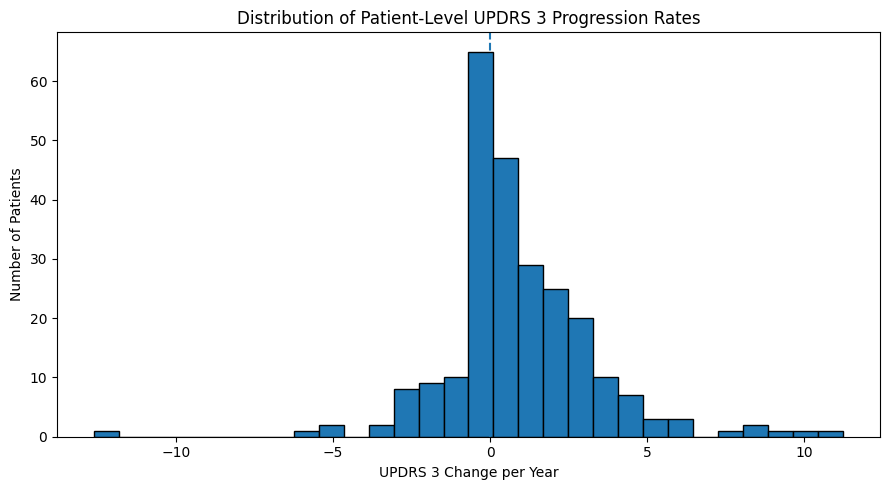

In [6]:
plt.figure(figsize=(9, 5))

plt.hist(
    patient_slopes["updrs3_slope_per_year"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("UPDRS 3 Change per Year")
plt.ylabel("Number of Patients")
plt.title("Distribution of Patient-Level UPDRS 3 Progression Rates")

plt.tight_layout()
plt.show()

In [7]:
first_last = (
    progression_data
    .sort_values(["patient_id", "visit_month"])
    .groupby("patient_id")
    .agg(
        first_month=("visit_month", "first"),
        last_month=("visit_month", "last"),
        first_updrs3=("updrs_3", "first"),
        last_updrs3=("updrs_3", "last")
    )
    .reset_index()
)

first_last["updrs3_change"] = (
    first_last["last_updrs3"] - first_last["first_updrs3"]
)

first_last["followup_months"] = (
    first_last["last_month"] - first_last["first_month"]
)

first_last.head()

,patient_id,first_month,last_month,first_updrs3,last_updrs3,updrs3_change,followup_months
0,55,0,60,15.0,56.0,41.0,60
1,942,0,96,20.0,39.0,19.0,96
2,1517,0,60,25.0,39.0,14.0,60
3,1923,0,36,0.0,1.0,1.0,36
4,2660,0,60,0.0,1.0,1.0,60


In [8]:
print("First-to-last UPDRS 3 change:")
print(first_last["updrs3_change"].describe())

print()

print("Follow-up duration in months:")
print(first_last["followup_months"].describe())

First-to-last UPDRS 3 change:
count    248.000000
mean       7.540323
std       13.036790
min      -25.000000
25%        0.000000
50%        3.000000
75%       13.000000
max       48.000000
Name: updrs3_change, dtype: float64

Follow-up duration in months:
count    248.000000
mean      68.274194
std       23.185692
min       12.000000
25%       48.000000
50%       72.000000
75%       84.000000
max      108.000000
Name: followup_months, dtype: float64


In [9]:
progression_summary = patient_slopes.merge(
    first_last,
    on="patient_id",
    how="left"
)

progression_summary.head()

,patient_id,updrs3_slope_per_month,updrs3_slope_per_year,first_month,last_month,first_updrs3,last_updrs3,updrs3_change,followup_months
0,55,0.513512,6.162147,0,60,15.0,56.0,41.0,60
1,942,0.177698,2.132374,0,96,20.0,39.0,19.0,96
2,1517,0.237013,2.844156,0,60,25.0,39.0,14.0,60
3,1923,0.041667,0.500000,0,36,0.0,1.0,1.0,36
4,2660,0.007143,0.085714,0,60,0.0,1.0,1.0,60


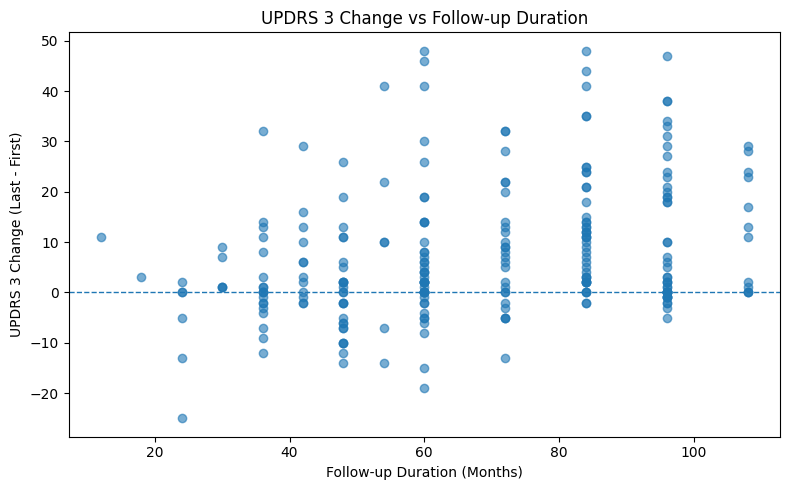

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    progression_summary["followup_months"],
    progression_summary["updrs3_change"],
    alpha=0.6
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Follow-up Duration (Months)")
plt.ylabel("UPDRS 3 Change (Last - First)")
plt.title("UPDRS 3 Change vs Follow-up Duration")

plt.tight_layout()
plt.show()

## Initial Findings

- UPDRS Part 3 progression varied substantially across patients.
- The **median progression rate was approximately 0.43 UPDRS 3 points per year**, while the mean was approximately **0.93 points per year**.
- About **66% of patients had a positive UPDRS 3 slope**, indicating higher motor examination scores over the course of their observed follow-up.
- About **31% of patients had a negative slope**, showing that UPDRS measurements do not increase consistently for every patient.
- The average first-to-last change in UPDRS 3 was approximately **7.5 points**, but follow-up duration varied between patients.
- Using a yearly progression slope accounts for these differences in follow-up time and provides a more comparable measure of progression between patients.
- These patient-level progression rates could later be used to investigate whether protein or peptide measurements are associated with **faster Parkinson's disease progression**.